In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(r"C:\Users\DELL\Downloads\loan_default_data.csv")

In [4]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nTarget counts:")
print(df["default"].value_counts(dropna=False))
print("\nMissing values:")
print(df.isna().sum())

Shape: (10000, 14)

Columns: ['customer_id', 'age', 'annual_income', 'credit_score', 'loan_amount', 'loan_tenure_months', 'interest_rate', 'dti', 'utilization', 'days_past_due', 'inquiries_6m', 'existing_loans', 'employment_type', 'default']

Target counts:
default
0    8574
1    1426
Name: count, dtype: int64

Missing values:
customer_id             0
age                     0
annual_income         200
credit_score          150
loan_amount             0
loan_tenure_months      0
interest_rate           0
dti                   100
utilization             0
days_past_due           0
inquiries_6m            0
existing_loans          0
employment_type         0
default                 0
dtype: int64


In [5]:
X = df.drop(columns=["customer_id", "days_past_due", "default"])
y = df["default"]

print(X.shape)
print(y.shape)

(10000, 11)
(10000,)


In [6]:
from sklearn.model_selection import train_test_split

# 20% final test data
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Remaining 80% ka 25% = total data ka 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nDefault rate:")
print("Train:", y_train.mean())
print("Validation:", y_val.mean())
print("Test:", y_test.mean())

Train: (6000, 11)
Validation: (2000, 11)
Test: (2000, 11)

Default rate:
Train: 0.14266666666666666
Validation: 0.1425
Test: 0.1425


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ["employment_type"]
numerical_cols = X_train.columns.drop(categorical_cols).tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numerical_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols)
    ]
)

# Training data se median aur categories learn hongi
X_train_processed = preprocessor.fit_transform(X_train)

# Wahi learned preprocessing validation aur test par apply hogi
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (6000, 14)
Validation: (2000, 14)
Test: (2000, 14)


In [8]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [9]:
import xgboost
print(xgboost.__version__)

3.4.1


In [10]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    eval_metric="auc",
    early_stopping_rounds=50,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

train_prob = xgb_model.predict_proba(X_train_processed)[:, 1]
val_prob = xgb_model.predict_proba(X_val_processed)[:, 1]

print("Best boosting round:", xgb_model.best_iteration + 1)
print("Train ROC-AUC:", roc_auc_score(y_train, train_prob))
print("Validation ROC-AUC:", roc_auc_score(y_val, val_prob))

Best boosting round: 85
Train ROC-AUC: 0.7844635252394587
Validation ROC-AUC: 0.7658083985473888


In [11]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)

val_pred = (val_prob >= 0.50).astype(int)

print("Validation confusion matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nClassification report:")
print(classification_report(y_val, val_pred, zero_division=0))

print("Validation average precision:",
      average_precision_score(y_val, val_prob))

Validation confusion matrix:
[[1710    5]
 [ 277    8]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92      1715
           1       0.62      0.03      0.05       285

    accuracy                           0.86      2000
   macro avg       0.74      0.51      0.49      2000
weighted avg       0.83      0.86      0.80      2000

Validation average precision: 0.37287700157476494


In [12]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (val_prob >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "flagged_customers": int(pred.sum())
    })

threshold_results = pd.DataFrame(results)
print(threshold_results.round(3).to_string(index=False))

 threshold  precision  recall    f1  flagged_customers
      0.10      0.206   0.874 0.334               1207
      0.15      0.268   0.709 0.389                753
      0.20      0.334   0.505 0.402                431
      0.25      0.408   0.365 0.385                255
      0.30      0.473   0.246 0.323                148
      0.40      0.593   0.112 0.189                 54
      0.50      0.615   0.028 0.054                 13


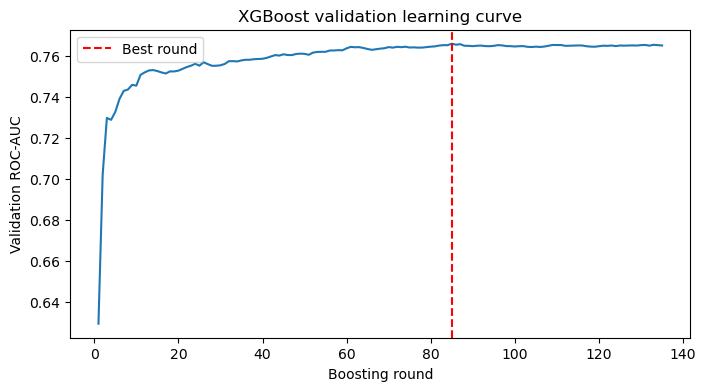

In [13]:
import matplotlib.pyplot as plt

history = xgb_model.evals_result()
val_auc = history["validation_0"]["auc"]

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(val_auc) + 1), val_auc)
plt.axvline(
    xgb_model.best_iteration + 1,
    color="red",
    linestyle="--",
    label="Best round"
)
plt.xlabel("Boosting round")
plt.ylabel("Validation ROC-AUC")
plt.title("XGBoost validation learning curve")
plt.legend()
plt.show()

In [14]:
trial_params = xgb_model.get_params()
trial_params["max_depth"] = 4

xgb_depth4 = XGBClassifier(**trial_params)

xgb_depth4.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

train_prob_depth4 = xgb_depth4.predict_proba(X_train_processed)[:, 1]
val_prob_depth4 = xgb_depth4.predict_proba(X_val_processed)[:, 1]

print("Best round:", xgb_depth4.best_iteration + 1)
print("Train AUC:", roc_auc_score(y_train, train_prob_depth4))
print("Validation AUC:", roc_auc_score(y_val, val_prob_depth4))
print("Validation AP:",
      average_precision_score(y_val, val_prob_depth4))

Best round: 72
Train AUC: 0.8098392465225797
Validation AUC: 0.761827016520894
Validation AP: 0.35556820277327406


In [15]:
final_model = xgb_model
final_threshold = 0.20

test_prob = final_model.predict_proba(X_test_processed)[:, 1]
test_pred = (test_prob >= final_threshold).astype(int)

print("Test ROC-AUC:", roc_auc_score(y_test, test_prob))
print("Test average precision:",
      average_precision_score(y_test, test_prob))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nTest classification report:")
print(classification_report(y_test, test_pred, zero_division=0))

Test ROC-AUC: 0.7420940105365454
Test average precision: 0.3499767387451386

Test confusion matrix:
[[1410  305]
 [ 134  151]]

Test classification report:
              precision    recall  f1-score   support

           0       0.91      0.82      0.87      1715
           1       0.33      0.53      0.41       285

    accuracy                           0.78      2000
   macro avg       0.62      0.68      0.64      2000
weighted avg       0.83      0.78      0.80      2000



In [16]:
feature_importance = pd.DataFrame({
    "feature": preprocessor.get_feature_names_out(),
    "importance": final_model.feature_importances_
}).sort_values("importance", ascending=False)

print(feature_importance.to_string(index=False))

                           feature  importance
                 num__credit_score    0.153895
                  num__utilization    0.116695
                          num__dti    0.096902
     cat__employment_type_Contract    0.080600
                num__interest_rate    0.077435
                 num__inquiries_6m    0.069981
   cat__employment_type_Unemployed    0.063685
     cat__employment_type_Salaried    0.054855
           num__loan_tenure_months    0.052139
               num__existing_loans    0.051249
                num__annual_income    0.050797
                  num__loan_amount    0.047927
                          num__age    0.047522
cat__employment_type_Self-employed    0.036318


In [17]:
%pip install shap

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ------------- -------------------------- 262.1/755.4 kB ? eta -:--:--
   --------------------------- ------------ 524.3/755.4 kB 1.3 MB/s eta 0:00:01
   ---------------------------------------- 755.4/755.4 kB 1.6 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


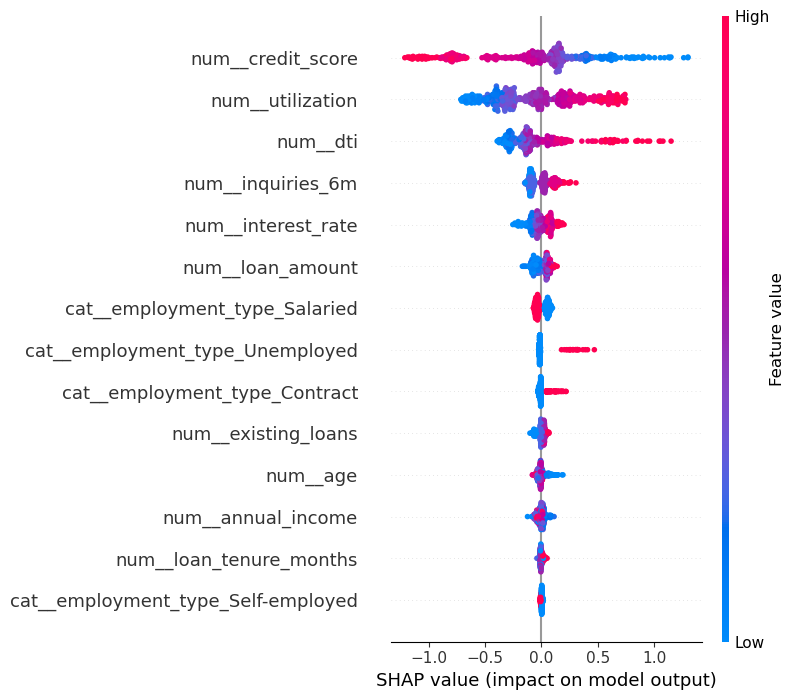

In [18]:
import shap
import pandas as pd

# Validation ke 500 customers: explanation ke liye
X_explain = pd.DataFrame(
    X_val_processed[:500],
    columns=preprocessor.get_feature_names_out()
)

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_explain)

shap.summary_plot(shap_values, X_explain)

In [19]:
import joblib
import numpy as np

model_bundle = {
    "preprocessor": preprocessor,
    "model": final_model,
    "threshold": final_threshold,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(model_bundle, "xgboost_loan_default.joblib")

# Reload
loaded = joblib.load("xgboost_loan_default.joblib")

# Raw data se predictions dobara banana
sample = X_test.iloc[:5][loaded["feature_columns"]]
sample_processed = loaded["preprocessor"].transform(sample)

loaded_prob = loaded["model"].predict_proba(sample_processed)[:, 1]
loaded_pred = (loaded_prob >= loaded["threshold"]).astype(int)

print("Probabilities:", loaded_prob)
print("Predictions:", loaded_pred)
print("Reload predictions match:",
      np.allclose(loaded_prob, test_prob[:5]))

Probabilities: [0.12706964 0.11112051 0.13790303 0.2611088  0.08195385]
Predictions: [0 0 0 1 0]
Reload predictions match: True
